In [1]:
#Import the Libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # Used alongside Spark for local visualization plotting
import seaborn as sns
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator,
)
from pyspark.ml.feature import OneHotEncoder, StringIndexer, StandardScaler, VectorAssembler
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType

In [2]:
# Initialize Spark Session
spark = SparkSession.builder \
    .appName("Bestseller_Prediction_Spark_Amazon") \
    .master("local[*]") \
    .getOrCreate()

In [3]:
# Read Data file
DATA_PATH = "C:\Datasets\AmazonBooks.csv"

df_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("multiLine", True)
    .option("quote", '"')
    .option("escape", '"')
    .option("encoding", "ISO-8859-1")
    .csv(DATA_PATH)
)

In [4]:
print("Number of rows:", df_spark.count())

df_spark.printSchema()

Number of rows: 600
root
 |-- Name: string (nullable = true)
 |-- Author: string (nullable = true)
 |-- User Rating: double (nullable = true)
 |-- Reviews: integer (nullable = true)
 |-- Price: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Genre: string (nullable = true)



In [5]:
# Show top 20 rows
df_spark.show()

+--------------------+--------------------+-----------+-------+-----+----+-----------+
|                Name|              Author|User Rating|Reviews|Price|Year|      Genre|
+--------------------+--------------------+-----------+-------+-----+----+-----------+
|10-Day Green Smoo...|            JJ Smith|        4.7|  17350|    8|2016|Non Fiction|
|   11/22/63: A Novel|        Stephen King|        4.6|   2052|   22|2011|    Fiction|
|12 Rules for Life...|  Jordan B. Peterson|        4.7|  18979|   15|2018|Non Fiction|
|1984 (Signet Clas...|       George Orwell|        4.7|  21424|    6|2017|    Fiction|
|5,000 Awesome Fac...|National Geograph...|        4.8|   7665|   12|2019|Non Fiction|
|A Dance with Drag...| George R. R. Martin|        4.4|  12643|   11|2011|    Fiction|
|A Game of Thrones...| George R. R. Martin|        4.7|  19735|   30|2014|    Fiction|
|A Gentleman in Mo...|         Amor Towles|        4.7|  19699|   15|2017|    Fiction|
|A Higher Loyalty:...|         James Comey|

In [6]:
# Initial row count
total_count = df_spark.count()

# Remove null values
df_spark = df_spark.na.drop()
clean_count = df_spark.count()

# Remove duplicates
df_spark = df_spark.dropDuplicates()
after_duplicates_count = df_spark.count()

# Remove rows where Price = 0
before_price_filter = after_duplicates_count
df_spark = df_spark.filter(df_spark["Price"] > 0)
rows_after = df_spark.count()

# Calculate removals
duplicates_removed = clean_count - after_duplicates_count
zero_price_removed = before_price_filter - rows_after

print(f"Rows after removing null values: {clean_count}")
print(f"Rows before cleaning: {total_count}")
print(f"Duplicate rows removed: {duplicates_removed}")
print(f"Rows with Price = 0 removed: {zero_price_removed}")
print(f"Rows remaining after all cleaning: {rows_after}")


Rows after removing null values: 600
Rows before cleaning: 600
Duplicate rows removed: 0
Rows with Price = 0 removed: 12
Rows remaining after all cleaning: 588


### Data Cleaning
Data cleaning was performed to improve the quality and reliability of the dataset before conducting exploratory data analysis and training the logistic regression model. Records containing missing values were removed to ensure completeness, duplicate records were eliminated to prevent bias caused by repeated observations, and books with a price of zero were excluded because they may not represent valid market transactions. 

In [7]:
# Create Best Seller column
from pyspark.sql import functions as F

# Convert Reviews to a numeric data type
df_spark = df_spark.withColumn(
    "Reviews",
    F.col("Reviews").cast("double")
)

# Calculate the exact median
median_reviews = df_spark.approxQuantile(
    "Reviews",
    [0.50],
    0.0
)[0]

print(f"Median review count: {median_reviews:,.0f}")

# Create a transparent proxy target
df_spark = df_spark.withColumn(
    "BestSeller",
    (F.col("Reviews") >= F.lit(median_reviews))
    .cast("integer")
)

# Check the resulting class distribution
df_spark.groupBy("BestSeller").agg(
    F.count("*").alias("NumberOfBooks")
).show()

# Calculate class proportions
df_spark.groupBy("BestSeller").agg(
    F.count("*").alias("NumberOfBooks")
).withColumn(
    "Percentage",
    F.round(
        F.col("NumberOfBooks") /
        df_spark.count() * 100,
        2
    )
).show()

Median review count: 9,198
+----------+-------------+
|BestSeller|NumberOfBooks|
+----------+-------------+
|         1|          295|
|         0|          293|
+----------+-------------+

+----------+-------------+----------+
|BestSeller|NumberOfBooks|Percentage|
+----------+-------------+----------+
|         1|          295|     50.17|
|         0|          293|     49.83|
+----------+-------------+----------+



### Explanation of Best Seller Creation
As the dataset did not contain a predefined bestseller indicator, a binary target variable named BestSeller was created using the number of reviews as a proxy measure of popularity. The Reviews column was first converted to a numeric data type, after which the median review count (9198) was calculated. Books with review counts greater than or equal to the median were assigned a value of 1 (BestSeller), while books with review counts below the median were assigned a value of 0 (Non-Bestseller). The resulting class distribution was then analysed to verify class balance. Approximately 50% of the books were classified as bestsellers and 50% as non-bestsellers, providing a balanced dataset suitable for training and evaluating a logistic regression model.

In [8]:
df_spark.show()

+--------------------+--------------------+-----------+-------+-----+----+-----------+----------+
|                Name|              Author|User Rating|Reviews|Price|Year|      Genre|BestSeller|
+--------------------+--------------------+-----------+-------+-----+----+-----------+----------+
|Divergent / Insur...|       Veronica Roth|        4.5|17684.0|    6|2014|    Fiction|         1|
|Harry Potter and ...|        J.K. Rowling|        4.9| 3146.0|   30|2017|    Fiction|         0|
|Joyland (Hard Cas...|        Stephen King|        4.5| 4748.0|   12|2013|    Fiction|         0|
|The Day the Crayo...|        Drew Daywalt|        4.8| 8922.0|    9|2014|    Fiction|         0|
|The Whole30: The ...|Melissa Hartwig U...|        4.6| 7508.0|   16|2017|Non Fiction|         0|
|Broke: The Plan t...|          Glenn Beck|        4.5|  471.0|    8|2010|Non Fiction|         0|
|Creative Haven Cr...|     Marjorie Sarnat|        4.8| 4022.0|    4|2015|Non Fiction|         0|
|Instant Pot Press..

In [9]:
# Convert Spark to Pandas
pdf = df_spark.toPandas()

In [10]:
# Dataset overview
print("Rows:", pdf.shape[0])
print("Columns:", pdf.shape[1])

Rows: 588
Columns: 8


In [11]:
pdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588 entries, 0 to 587
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         588 non-null    object 
 1   Author       588 non-null    object 
 2   User Rating  588 non-null    float64
 3   Reviews      588 non-null    float64
 4   Price        588 non-null    int32  
 5   Year         588 non-null    int32  
 6   Genre        588 non-null    object 
 7   BestSeller   588 non-null    int32  
dtypes: float64(2), int32(3), object(3)
memory usage: 30.0+ KB


In [12]:
# Get Summary Statistics
pdf.describe()

,User Rating,Reviews,Price,Year,BestSeller
count,588.000000,588.000000,588.000000,588.000000,588.000000
mean,4.624490,13999.232993,13.183673,2014.511905,0.501701
std,0.226398,14715.494695,10.438443,3.478069,0.500423
min,3.300000,37.000000,1.000000,2009.000000,0.000000
25%,4.500000,4631.750000,7.000000,2011.000000,0.000000
50%,4.700000,9243.500000,11.000000,2015.000000,1.000000
75%,4.800000,19576.000000,16.000000,2018.000000,1.000000
max,4.900000,120727.000000,105.000000,2020.000000,1.000000


### Interpretation
**User Rating**
  - The average user rating is 4.62, indicating that most books in the dataset receive very positive reviews from readers.
  - Ratings range from 3.3 to 4.9, with a median of 4.7
  - The relatively small standard deviation (0.22) suggests that ratings are tightly clustered around the mean, meaning there is little variation in user ratings across books.
  - This limited variability may explain why User Rating showed only a weak correlation with bestseller status
    
**Reviews**
 - Books receive an average of approximately 13,999 reviews.
 - The median number of reviews is 9,243.5, which is substantially lower than the mean.
 - The large standard deviation (14,715.49) and wide range (37 to 120,727 reviews) indicate considerable variation in review counts.
   
**Price**
 - The average book price is approximately 13.18 dollars.
 - The median price is 11 dollars, indicating that at least half of the books are priced at 11 dollars or below.
 - Prices range from 1 to 105 dollars, with a standard deviation of 10.44.

** Year**
 - The books span from 2009 to 2020.
 - The dataset is relatively evenly distributed across the study period, providing representation of books from multiple years.

**BestSeller**
 - The mean value of 0.5017 and median of 1 indicate that half of the observations belong to the bestseller class.
 - The balanced distribution between bestseller and non-bestseller classes is advantageous for logistic regression because it reduces the risk of class imbalance affecting model performance.

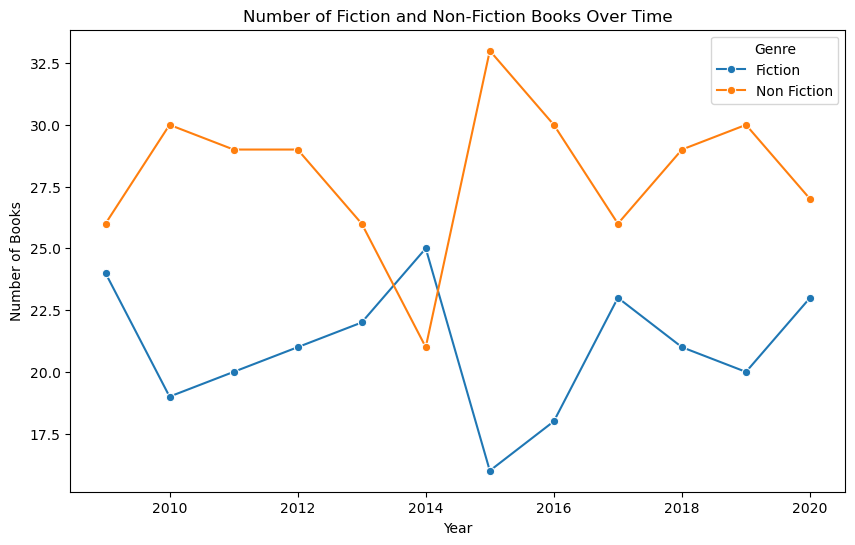

In [13]:
# Compare the count of Genres
genre_year = (
    pdf.groupby(['Year','Genre'])
       .size()
       .reset_index(name='Count')
)

plt.figure(figsize=(10,6))

sns.lineplot(
    data=genre_year,
    x='Year',
    y='Count',
    hue='Genre',
    marker='o'
)

plt.title('Number of Fiction and Non-Fiction Books Over Time')
plt.ylabel('Number of Books')
plt.show()


#### The chart shows how the popularity of Fiction and Non-Fiction books changed between 2009 and 2019. Since the distribution varies over time, both Year and Genre may contribute useful predictive information.

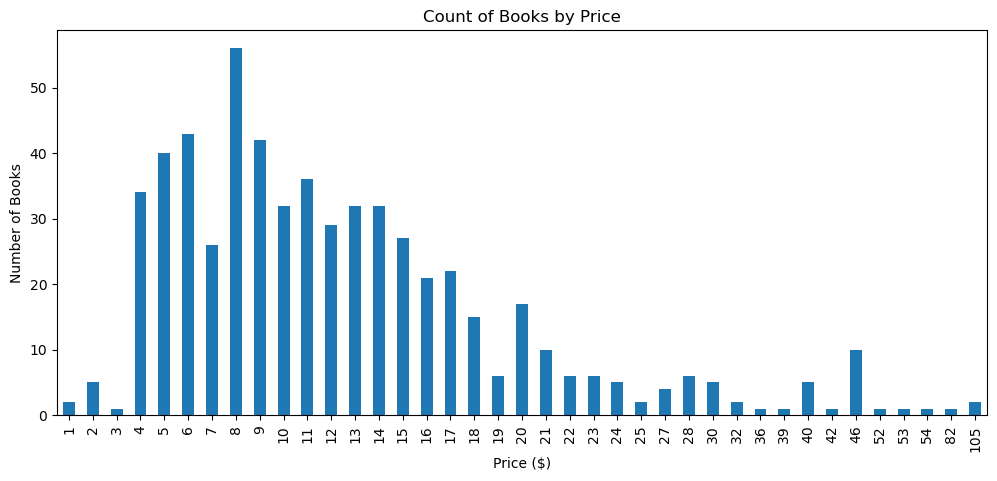

In [14]:
# Count of Books per Price
price_count = (
    pdf['Price']
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(12,5))

price_count.plot(kind='bar')

plt.title('Count of Books by Price')
plt.xlabel('Price ($)')
plt.ylabel('Number of Books')

plt.show()

### Key Observations
The chart indicates that bestselling books are predominantly priced between 4 and 15 dollars, with 8 dollars being the most common price point. The distribution is highly right-skewed, as the frequency of books decreases substantially at higher prices and only a few books are priced above 40 dollars. These findings suggest that while price varies across books, most bestsellers tend to be relatively inexpensive.

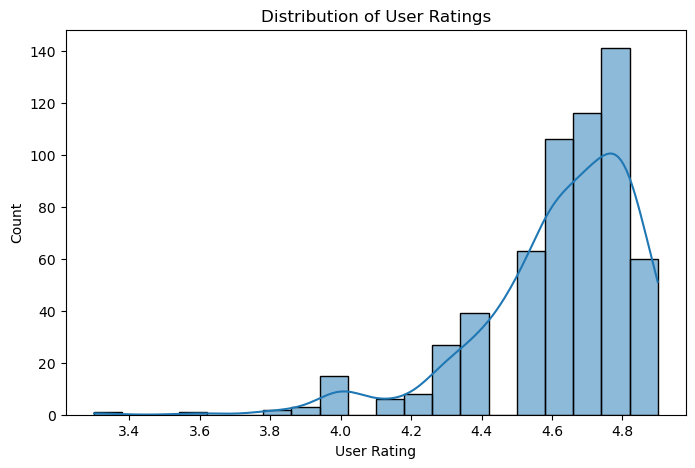

In [15]:
# User Rating Distribution
plt.figure(figsize=(8,5))

sns.histplot(
    pdf['User Rating'],
    bins=20,
    kde=True
)

plt.title('Distribution of User Ratings')

plt.show()

### Key Observations
The histogram shows that book ratings are heavily concentrated between 4.5 and 4.9, with a peak around 4.7–4.8. The distribution is negatively skewed, indicating that low-rated books are rare while highly rated books are common. This suggests that most books in the dataset receive positive reader feedback.

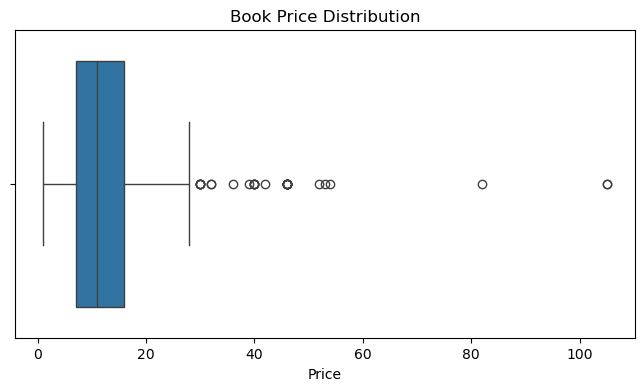

In [16]:
# Boxplot of Price
plt.figure(figsize=(8,4))

sns.boxplot(x=pdf['Price'])

plt.title('Book Price Distribution')

plt.show()

### The box plot shows that most book prices are concentrated at the lower end of the price range, while a small number of books are priced much higher.
 - The median price (middle line inside the box) is approximately 11 – 12 dollars, indicating that half of the books are priced below this value and half above it.
The interquartile range (IQR), represented by the box, spans roughly from 7 - 15 dollars. This means that the middle 50% of books are priced within this range.
The lower whisker extends to around 1 – 2 dollars, showing that some books are sold at very low prices.
The upper whisker extends to approximately 28 dollars, indicating that most non-outlier book prices are below this value.

 - There are numerous outliers beyond the upper whisker, with prices ranging from approximately 30 to 55 dollars.
 - Two extreme outliers are visible at approximately 80 and 105 dollars.
 - These outliers suggest that a small number of books are significantly more expensive than the majority of titles
 - The majority of books are priced between approximately 7 and 15 dollars, with a median price of around 11 – 12 dollars. The distribution is strongly right-skewed due to several high-priced outliers, including books priced above 80 and 100 dollars. This suggests that expensive books are relatively rare compared to the overall collection.

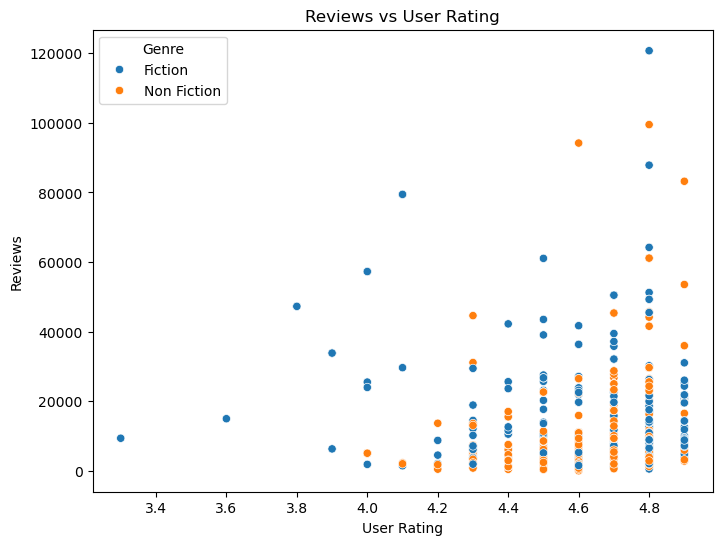

In [17]:
# Reviews vs Ratings
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pdf,
    x='User Rating',
    y='Reviews',
    hue='Genre'
)

plt.title('Reviews vs User Rating')

plt.show()

 - The majority of points are concentrated between 4.3 and 4.9 on the User Rating axis.
 - Very few books have ratings below 4.0.
 - This suggests that the bestselling books in the dataset are generally well rated by readers.
 - Books with ratings around 4.8–4.9 can have anywhere from a few hundred reviews to over 120,000 reviews.
 - Similarly, books with ratings around 4.2–4.5 also show a wide range of review counts.
 - This indicates that a higher rating does not necessarily result in more reviews.
 - Both genres appear across most rating levels.
 - Both Fiction and Non Fiction books achieve high review counts.
- There is no obvious visual evidence that one genre consistently receives higher ratings or more reviews than the other.

### Conclusion
The scatter plot suggests a weak positive or negligible correlation between User Rating and Reviews. While most bestselling books receive ratings above 4.0, books with similar ratings can have vastly different numbers of reviews. This indicates that user rating alone is not a strong predictor of how many reviews a book will receive

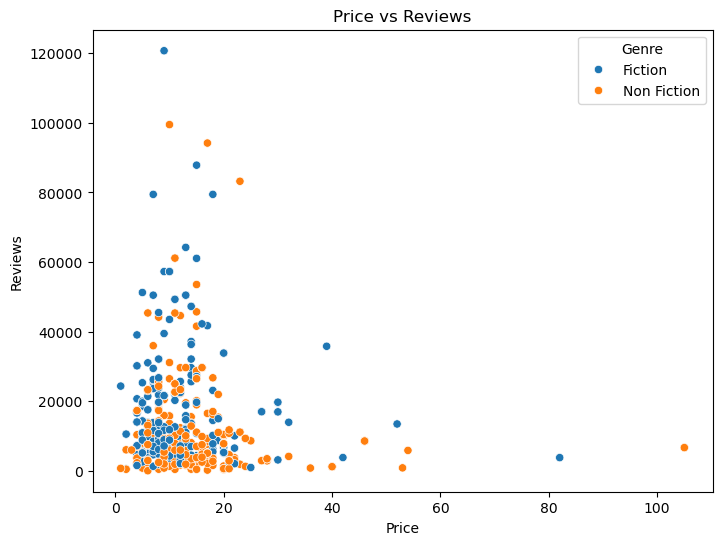

In [18]:
# Price vs Reviews
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pdf,
    x='Price',
    y='Reviews',
    hue='Genre'
)

plt.title('Price vs Reviews')
plt.xlabel('Price')
plt.ylabel('Reviews')

plt.show()

 - The majority of books are priced between 5 and 20.
 - Very few books have prices above 30.
 - This observation aligns with the earlier box plot, which showed that most book prices are concentrated at the lower end of the price range.
 - Books with similar prices have vastly different numbers of reviews.
 - The books with the highest review counts are generally priced below 20.
 - The most-reviewed book in the dataset has approximately 120,000 reviews and is priced around 10.
 - There are several price outliers, including books priced around 40, 55, 80, and 105.
 - Most of these expensive books have relatively low review counts compared to the most popular books.
 - Both Fiction and Non Fiction books are concentrated in the lower-price range.
 - Both genres contain books with high and low review counts.

### Conclusion

 - The scatter plot indicates a weak negative or negligible relationship between Price and Reviews. 
 - Books with the highest numbers of reviews are generally found in the lower-to-moderate price range, while higher-priced books tend to attract fewer reviews.

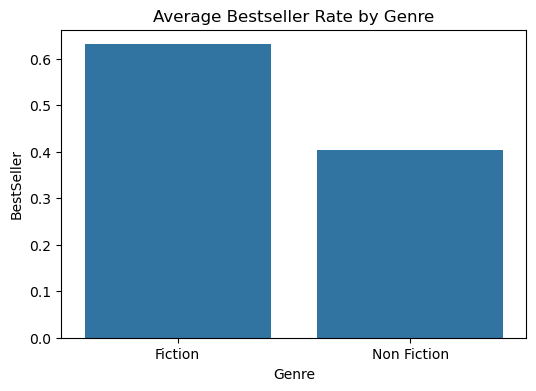

In [19]:
# Best seller by Genre
genre_bestseller = (
    pdf.groupby('Genre')['BestSeller']
       .mean()
       .reset_index()
)

plt.figure(figsize=(6,4))

sns.barplot(
    data=genre_bestseller,
    x='Genre',
    y='BestSeller'
)

plt.title('Average Bestseller Rate by Genre')

plt.show()

#### This bar chart compares the average bestseller rate between Fiction and Non Fiction books.
 - Fiction has an average bestseller rate of approximately 0.63 (63%).
 - Non Fiction has an average bestseller rate of approximately 0.41 (41%).

Although Non-Fiction books outnumber Fiction books in the dataset across most years as illustrated above with the line chart, Fiction books exhibit a substantially higher bestseller rate (approximately 63% compared to 40% for Non-Fiction). This indicates that while Non-Fiction titles are more prevalent, a larger proportion of Fiction books meet the criteria used to classify books as bestsellers. Therefore, Genre appears to be an important predictor of bestseller status, with Fiction books having a higher likelihood of being classified as bestsellers despite representing a smaller share of the overall dataset.

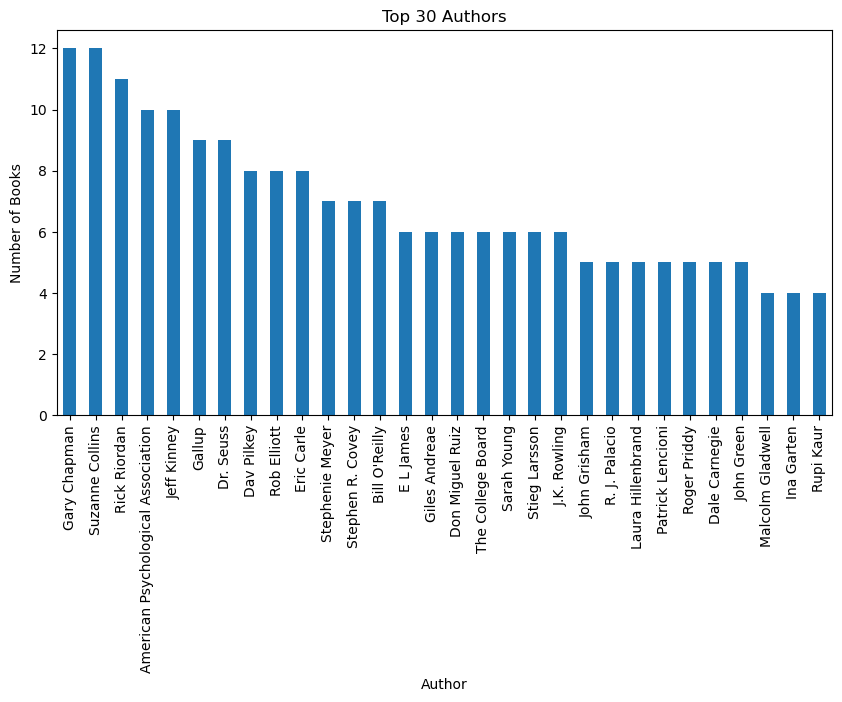

In [20]:
# Top authors
plt.figure(figsize=(10,5))

pdf['Author'].value_counts().head(30).plot(
    kind='bar'
)

plt.title('Top 30 Authors')
plt.ylabel('Number of Books')

plt.show()

This chart identifies authors with the most records in the dataset. It describes representation in the sample, not necessarily sales ranking or author quality. Author frequency may also be affected by the number of titles, editions or years represented

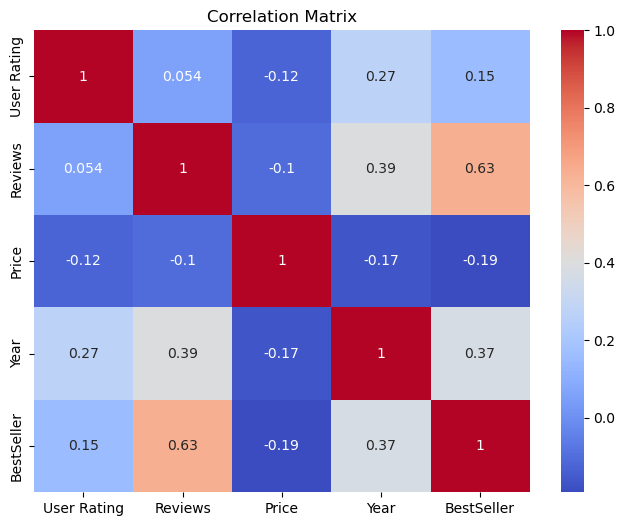

In [21]:
# Correlation Heat Map
numeric_cols = [
    'User Rating',
    'Reviews',
    'Price',
    'Year',
    'BestSeller'
]

plt.figure(figsize=(8,6))

sns.heatmap(
    pdf[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')

plt.show()

Correlation values range from -1 to +1:

 - +1 = Perfect positive relationship
 - 0 = No linear relationship
 - -1 = Perfect negative relationship

**Relationship with BestSeller:**

| Variable   |Correlation with BestSeller       |  Interpretation |
|:-----------------------|:------------------|-----------:|
| Review                 | 0.63  |       Strong positive correlation |
| Year                   | 0.37     |       Moderate positive correlation |
| Price                    | -0.19 |       Weak negative correlation |
| User Rating                    |0.15 |       Weak positive correlation |


In [22]:
# Encode Genre
from pyspark.ml.feature import StringIndexer

genre_indexer = StringIndexer(
    inputCol="Genre",
    outputCol="GenreIndex"
)


In [23]:

# Fit the indexer
genre_model = genre_indexer.fit(df_spark)

# Create GenreIndex column
df_spark = genre_model.transform(df_spark)

In [24]:
df_spark.select(
    "Genre",
    "GenreIndex"
).show()

+-----------+----------+
|      Genre|GenreIndex|
+-----------+----------+
|    Fiction|       1.0|
|    Fiction|       1.0|
|    Fiction|       1.0|
|    Fiction|       1.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|    Fiction|       1.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|    Fiction|       1.0|
|    Fiction|       1.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|Non Fiction|       0.0|
|    Fiction|       1.0|
+-----------+----------+
only showing top 20 rows


In [25]:
# Encode Author
author_indexer = StringIndexer(
    inputCol="Author",
    outputCol="AuthorIndex"
)

# Fit the auther indexer
author_model = author_indexer.fit(df_spark)

# Create author_indexer column
df_spark = author_model.transform(df_spark)

df_spark.select(
    "Author",
    "AuthorIndex"
).show()

+--------------------+-----------+
|              Author|AuthorIndex|
+--------------------+-----------+
|       Veronica Roth|       39.0|
|        J.K. Rowling|       16.0|
|        Stephen King|       37.0|
|        Drew Daywalt|       46.0|
|Melissa Hartwig U...|       55.0|
|          Glenn Beck|       51.0|
|     Marjorie Sarnat|      105.0|
|      Jennifer Smith|       99.0|
|         Rob Elliott|        9.0|
|          Dav Pilkey|        7.0|
|                  DK|       77.0|
|         Marty Noble|      222.0|
|       Anthony Doerr|       71.0|
|    Abraham Verghese|       64.0|
|     David Zinczenko|       82.0|
| Pretty Simple Press|      245.0|
|         Jim Collins|       31.0|
|         Rob Elliott|        9.0|
|     Timothy Ferriss|      121.0|
|        Paulo Coelho|      240.0|
+--------------------+-----------+
only showing top 20 rows


In [26]:
df_spark.printSchema()

root
 |-- Name: string (nullable = true)
 |-- Author: string (nullable = true)
 |-- User Rating: double (nullable = true)
 |-- Reviews: double (nullable = true)
 |-- Price: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Genre: string (nullable = true)
 |-- BestSeller: integer (nullable = true)
 |-- GenreIndex: double (nullable = false)
 |-- AuthorIndex: double (nullable = false)



In [27]:
# 1. Feature selection
feature_cols = [
    "User Rating",
    "Reviews",
    "Price",
    "Year",
    "GenreIndex",
    "AuthorIndex"
]

# 2. Train/Test Split
train_df, test_df = df_spark.randomSplit([0.8, 0.2], seed=42)


In [28]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

train_df = assembler.transform(train_df)
test_df = assembler.transform(test_df)

In [29]:
# Fit the scaler only on the training data:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(train_df)

**Why fit scaler to training data?** - To prevent data leak
 - The scaler learns 80% of the data to prevent the model to indirectly see info fro test set before evaluation. The result of not doing that:
   - The model no longer represents a true real-world scenario.
   - Evaluation metrics become overly optimistic.
   - Accuracy may appear higher than it really is.


In [30]:
# Transform both datasets
train_df = scaler_model.transform(train_df)
test_df = scaler_model.transform(test_df)

In [31]:
# Prepare data for your custom logistic regression
train_pdf = train_df.select("features", "BestSeller").toPandas()
test_pdf = test_df.select("features", "BestSeller").toPandas()

# Show number of records
print(f"Training records: {len(train_pdf)}")
print(f"Testing records: {len(test_pdf)}")

# Show percentage split
total_records = len(train_pdf) + len(test_pdf)

print(f"Training percentage: {len(train_pdf)/total_records:.2%}")
print(f"Testing percentage: {len(test_pdf)/total_records:.2%}")

Training records: 497
Testing records: 91
Training percentage: 84.52%
Testing percentage: 15.48%


In [32]:
# Convert Spark vectors into NumPy arrays
X_train = np.array(train_pdf['features'].apply(lambda x: x.toArray()).tolist())
y_train = train_pdf['BestSeller'].values

X_test = np.array(test_pdf['features'].apply(lambda x: x.toArray()).tolist())
y_test = test_pdf['BestSeller'].values

In [33]:
# Add intercept term
X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

# Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [34]:
# Logistic Regression from scratch
class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, iterations=1000):
        self.learning_rate = learning_rate
        self.iterations = iterations

    def fit(self, X, y):

        self.weights = np.zeros(X.shape[1])

        for i in range(self.iterations):

            z = np.dot(X, self.weights)
            predictions = sigmoid(z)

            gradient = (1 / len(y)) * np.dot(X.T, (predictions - y))

            self.weights -= self.learning_rate * gradient

    def predict_proba(self, X):
        return sigmoid(np.dot(X, self.weights))

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)


### Explanation of the Logistic Regression from Scratch Code
 - A Logistic Regression algorithm was implemented from scratch using NumPy. 
 - A sigmoid activation function was used to convert linear predictions into probabilities between 0 and 1, representing the likelihood that a book would be classified as a bestseller.
 - Model parameters were initialized to zero and optimized through gradient descent, where weights were repeatedly adjusted to minimize prediction error over a specified number of iterations.
 - After training, the model generated probabilities for each book, which were converted into binary classifications using a threshold of 0.5. Books with predicted probabilities greater than or equal to 0.5 were classified as bestsellers, while those below 0.5 were classified as non-bestsellers.

In [35]:
# Train m=Model
model = LogisticRegressionScratch(
    learning_rate=0.01,
    iterations=1000
)

model.fit(X_train, y_train)

print("Model Training Complete")

Model Training Complete


In [36]:
# Generate Prediction
y_pred = model.predict(X_test)

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

#print("Confusion Matrix:")
# print(cm)

In [38]:
# Retrained Model
model_v2 = LogisticRegressionScratch(
    learning_rate=0.05,
    iterations=3000
)

model_v2.fit(X_train, y_train)

y_pred_v2 = model_v2.predict(X_test)

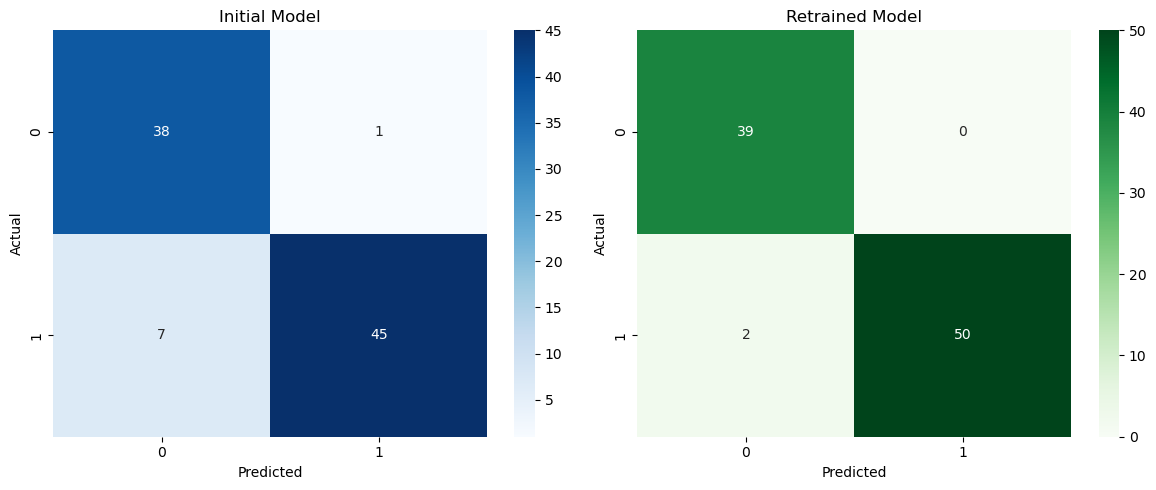

In [39]:
# Confusion Matrices Side by Side
# Original model
cm1 = confusion_matrix(y_test, y_pred)

# Retrained model
cm2 = confusion_matrix(y_test, y_pred_v2)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=ax[0]
)

ax[0].set_title('Initial Model')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=ax[1]
)

ax[1].set_title('Retrained Model')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Interpretation of the Confusion Matrices

### Initial Model
 - True Negatives (TN) = 38
    - 38 non-bestseller books were correctly identified.
 - False Positives (FP) = 1
    - 1 non-bestseller book was incorrectly classified as a bestseller.
 - False Negatives (FN) = 7
   - 7 bestseller books were incorrectly classified as non-bestsellers.
 - True Positives (TP) = 45
    - 45 bestseller books were correctly identified.
### Interpretation of the Initial Model
The initial model performed reasonably well, correctly classifying most books. However, the model struggled more with identifying actual bestsellers, as shown by the 7 false negatives. In a publishing context, these misclassifications are significant because potentially successful books could be overlooked

### Retrained Model
 - True Negatives (TN) = 39
    - All non-bestseller books were correctly identified.
 - False Positives (FP) = 0
    - No non-bestseller books were incorrectly classified as bestsellers.
 - False Negatives (FN) = 2
   - Only 2 bestseller books were incorrectly classified as non-bestsellers.
 - True Positives (TP) = 50
    - 50 bestseller books were correctly identified.
### Interpretation of the Retrained Model
The retrained model shows a substantial improvement over the initial model. It eliminated false positives entirely and reduced false negatives from 7 to 2. This indicates that the model became more effective at identifying bestseller books while maintaining perfect classification of non-bestsellers.

In [40]:
# Matrics Comparison
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Initial Model': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    'Retrained Model': [
        accuracy_score(y_test, y_pred_v2),
        precision_score(y_test, y_pred_v2),
        recall_score(y_test, y_pred_v2),
        f1_score(y_test, y_pred_v2)
    ]
})

results['Improvement'] = (
    results['Retrained Model']
    - results['Initial Model']
)

print("Comparison of the Performance Metrics of Initial and Retrained Models")
print(results.round(4))

Comparison of the Performance Metrics of Initial and Retrained Models
      Metric  Initial Model  Retrained Model  Improvement
0   Accuracy         0.9121           0.9780       0.0659
1  Precision         0.9783           1.0000       0.0217
2     Recall         0.8654           0.9615       0.0962
3   F1-Score         0.9184           0.9804       0.0620


## Accuracy
 - The initial model achieved an accuracy of 91.21%, meaning it correctly classified approximately 91 out of every 100 books.
 - The retrained model improved accuracy to 97.80%, representing an increase of 6.59 percentage points.
 - This improvement indicates that the retrained model made fewer overall classification errors.

## Precision
 - The initial model achieved a precision of 97.83%.
 - The retrained model achieved a perfect precision of 100%.
 - This means that every book predicted as a bestseller by the retrained model was actually a bestseller.
 - The improvement aligns with the confusion matrix, where the retrained model reduced false positives from 1 to 0.

## Recall
 - Recall increased from 86.54% to 96.15%, an improvement of 9.62 percentage points.
 - This is the largest improvement among the four metrics.
 - The higher recall indicates that the retrained model was significantly better at identifying actual bestselling books.
 - This result is consistent with the reduction in false negatives from 7 to 2 observed in the confusion matrices.

## F1-Score
 - The F1-Score increased from 91.84% to 98.04%, an improvement of 6.20 percentage points.
 - Since the F1-Score balances Precision and Recall, the increase demonstrates that the retrained model achieved a better overall balance between correctly identifying bestsellers and avoiding incorrect predictions.

## **Overall Evaluation**

The retrained logistic regression model outperformed the initial model across all evaluation metrics. Although the initial model already demonstrated strong predictive performance, retraining the model with adjusted parameters resulted in higher Accuracy, Precision, Recall, and F1-Score. The most notable improvement was in Recall, indicating that the retrained model became much more effective at identifying actual bestseller books while maintaining perfect Precision. Combined with the confusion matrix results, these metrics confirm that the retrained model is more reliable and should be selected as the final model for predicting whether a book will become a bestseller.

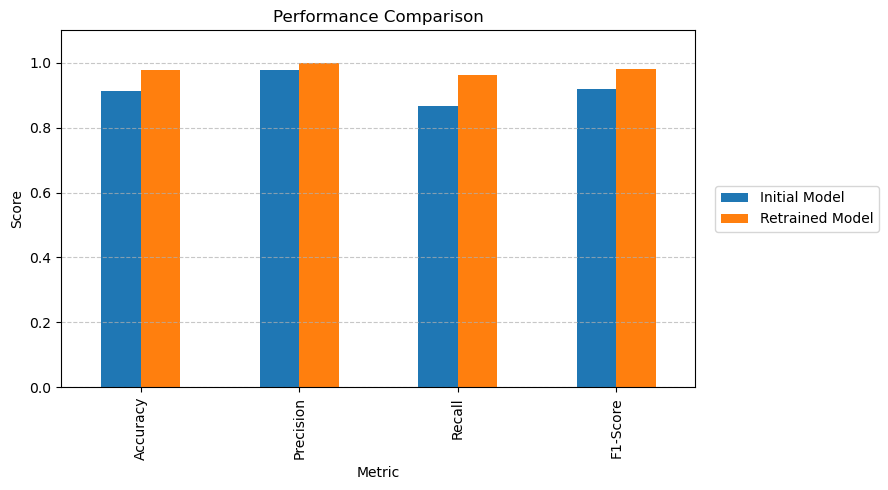

In [41]:
# Performance Matrix Comparison chart
results_plot = results.set_index('Metric')[
    ['Initial Model', 'Retrained Model']
]

results_plot.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Move legend outside the chart
plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.show()